# Geothermal Energy

## Learning goals

After this lesson you should be able to:

- distinguish geothermal gradient, heat flux, thermal power, gross electrical power, and net electrical power;
- use Kelvin correctly in thermodynamic efficiency calculations;
- estimate heat carried by produced fluid;
- include conversion efficiency, parasitic load, and production decline;
- implement validated Python functions and scenario plots;
- explain why temperature alone does not establish a viable geothermal resource.

Electricity generation requires useful heat plus a way to transport it to the surface. Conventional hydrothermal systems rely on heat, fluid, and permeability. Enhanced geothermal systems create or improve fluid pathways, while closed-loop systems circulate fluid in sealed wells [U.S. Department of Energy, 2025](#reference-doeGeothermalElectricity); [U.S. Department of Energy, 2025](#reference-doeEGS). Dry steam, flash steam, and binary-cycle plants use different surface processes and operating ranges.

<!-- expanded-theory:geothermal:start -->

## Physical description: useful heat from the subsurface

Geothermal energy is thermal energy in the Earth. A geothermal project does not produce energy merely by drilling to a high temperature: it needs a technically usable heat resource, a way to transfer heat to the surface, a suitable conversion or direct-use system, and an operating strategy that manages the subsurface response. Temperature, accessible fluid flow, pressure, chemistry and permeability all matter [Grant & Bixley, 2011](#reference-grant2011).

Heat within the Earth includes contributions from its formation and radioactive decay. At a local project scale, however, the important question is how heat reaches and is stored in the reservoir and how quickly it can be extracted. Natural replenishment does not guarantee that a particular well field can support an arbitrary extraction rate. Some systems can be operated for long periods, while excessive drawdown, cooling or fluid-management problems can limit output. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.5.

### Resource and utilization categories

| System or use | Description | Consequence for modelling |
|---|---|---|
| Hydrothermal resource | Naturally occurring hot fluid in permeable rock | Need reservoir pressure, temperature, flow pathways and fluid properties |
| Enhanced geothermal system (EGS) | Improves or creates fluid pathways in hot rock | Hydraulic connectivity, stimulation response and reservoir management become central |
| Closed-loop subsurface system | Circulates a working fluid through sealed underground conduits | Heat transfer through the well and surrounding formation can constrain output |
| Direct heat use | Delivers heat to a suitable process, building or heat network | Calculate useful thermal energy at the delivery temperature, not electrical output |
| Geothermal power generation | Converts a portion of extracted heat into electricity | Include cycle efficiency, cooling and parasitic electricity consumption |
| Ground-source heat pump | Uses the ground as a heat source or sink with electrical compressor work | Track electricity input and heat delivery; this is not geothermal electricity generation |

*Source for these definitions/calculations:* [Grant & Bixley, 2011](#reference-grant2011), Chapter 2; [U.S. Department of Energy, 2025](#reference-doeEGS); [U.S. Department of Energy, 2025](#reference-doeGeothermalElectricity). Heat-pump accounting: Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle).

Hydrothermal, EGS and closed-loop describe aspects of the subsurface system; dry-steam, flash and binary describe surface electricity-conversion arrangements. These classifications answer different questions and should not be used interchangeably. The supplied Grant and Bixley book develops reservoir concepts and simplified models; DiPippo is additional reading for power-conversion systems [Grant & Bixley, 2011](#reference-grant2011); [DiPippo, 2016](#reference-diPippo2016geothermal).

## Reservoir terms and transport processes

**Porosity** is the fraction of bulk rock volume occupied by pores or voids. **Permeability** describes the medium's ability to transmit fluid; connected pathways matter, so high porosity alone does not guarantee a productive well. Fractures can dominate fluid flow even when matrix permeability is low. **Transmissivity** incorporates the ability of a formation interval to transmit fluid over its effective thickness and depends on the convention used. [Grant & Bixley, 2011](#reference-grant2011), §§2.3–2.5, §3.3.1 and §3.7.

**Reservoir pressure** helps drive fluid toward a producing well, while pressure decline can reduce deliverability or increase pumping requirements. **Production wells** bring fluid to the surface; **injection wells** return fluid or supply circulation. Injection can help manage fluid mass and pressure, but poorly placed or strongly connected injection can cause premature cooling at producers. **Thermal breakthrough** is the arrival of a cooling influence along flow paths, not simply the passage of one calendar year [Grant & Bixley, 2011](#reference-grant2011).

A conceptual fluid-flow relationship is Darcy's law. For a one-dimensional horizontal, single-phase flow without a gravity term, [Grant & Bixley, 2011](#reference-grant2011), §§2.3–2.5, §3.3.1 and §3.7.

$$q_D=-\frac{k_{perm}}{\mu}\frac{dp}{dx}.$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§2.3–2.5, §3.3.1 and §3.7.

$q_D$ is Darcy flux in m/s, $k_{perm}$ is intrinsic permeability in m², $\mu$ is dynamic viscosity in Pa s, and $dp/dx$ is pressure gradient in Pa/m. The negative sign represents flow toward decreasing pressure. Actual geothermal flow may involve gravity, temperature-dependent properties, fractures and multiple phases, so this reduced relationship is not a complete well model. It explains why temperature alone cannot establish producible mass flow. [Grant & Bixley, 2011](#reference-grant2011), §§2.3–2.5, §3.3.1 and §3.7.

### Conduction and convection

Conduction transfers heat through a material without bulk transport of that material. Advection carries heat with moving fluid; buoyancy-driven circulating flow is commonly described as convection. In low-permeability conductive regions, a temperature gradient can help estimate deeper temperature over an appropriate interval. In permeable convecting systems, simple downward extrapolation of the shallow gradient may be misleading [Grant & Bixley, 2011](#reference-grant2011).

The linear conductive approximation is $T(z)=T_0+G_Tz$, where the depth coordinate and gradient must use matching units. If depth is in kilometres and gradient in °C/km, the product is a temperature difference in °C. This is a local model, not a universal rule that temperature always rises at one fixed rate everywhere. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

Fourier's law is

$$\mathbf q=-k_T\nabla T,$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

where thermal conductivity $k_T$ is W/(m K) and heat flux $\mathbf q$ is W/m². Thermal conductivity and intrinsic permeability are different physical properties; separate symbols help avoid confusion. If depth $z$ is positive downward and temperature rises downward, the conductive heat-flux vector points upward. For conductivity 2.5 W/(m K) and gradient 30 K/km, the upward heat-flux magnitude is $2.5(30/1000)=0.075$ W/m². A gradient is not itself a heat flux. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

## The surface plant and its energy boundaries

A typical conversion chain is **reservoir → production well → fluid collection/separation or heat exchanger → power cycle → generator → cooling/auxiliaries → reinjection**, with the detailed route depending on fluid state and technology. Pressure losses, pumping work and heat losses occur between reservoir and delivered output. [U.S. Department of Energy, 2025](#reference-doeGeothermalElectricity); reservoir-to-well limits: [Grant & Bixley, 2011](#reference-grant2011), Chapter 2.

### Dry-steam, flash and binary conversion

**Dry-steam plants** use a suitable steam resource to drive a turbine. **Flash plants** reduce the pressure of sufficiently hot liquid so that part of it vaporizes; a separator supplies steam to a turbine while residual liquid follows its own handling or reinjection path. **Binary plants** transfer geothermal heat through an exchanger to a separate working-fluid cycle. The geothermal fluid and the turbine working fluid therefore need not be the same fluid. [U.S. Department of Energy, 2025](#reference-doeGeothermalElectricity); [Grant & Bixley, 2011](#reference-grant2011), Chapter 2.

The plant type must match the temperature, pressure, phase state and chemistry of the resource. There is no single efficiency that applies to all geothermal plants. Cooling conditions and auxiliary demand also affect exported electricity. The course's constant-efficiency, single-phase calculation is most useful for learning heat-to-electricity accounting; it is not a detailed flash or binary cycle simulation [Grant & Bixley, 2011](#reference-grant2011); [U.S. Department of Energy, 2025](#reference-doeGeothermalElectricity).

DiPippo's fourth edition is a supplementary textbook covering power-conversion systems and case studies. Its publisher lists a late-2015 release while the copyright/edition page identifies 2016; this course cites the 2016 edition year. Current plant counts should not be inferred from the historical statistics in that edition [DiPippo, 2016](#reference-diPippo2016geothermal).

## Thermal power: mass flow and enthalpy

For a steady heat exchanger with negligible shaft work and changes in kinetic and potential energy, the heat removed from the geothermal stream is [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6; [Foster et al., 2010](#reference-foster2010), §3.8.1, applied to the stated steady-flow boundary.

$$\dot Q_{extracted}=\dot m(h_p-h_r),$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6; [Foster et al., 2010](#reference-foster2010), §3.8.1, applied to the stated steady-flow boundary.

where $\dot m$ is mass flow in kg/s, and $h_p$ and $h_r$ are specific enthalpies at the chosen production and return states. With $h$ in J/kg, output is W; with $h$ in kJ/kg, output is kW. This neglects heat leakage between the specified measurement states and the heat exchanger; it is the heat extracted from the stream under the defined boundary, not necessarily all the stored heat in the reservoir. [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6; [Foster et al., 2010](#reference-foster2010), §3.8.1, applied to the stated steady-flow boundary.

For a single-phase liquid with approximately constant specific heat, [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6; [Foster et al., 2010](#reference-foster2010), §3.8.1, applied to the stated steady-flow boundary.

$$h_p-h_r\approx c_p(T_p-T_r),\qquad
P_{th}=\dot m c_p(T_p-T_r).$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6; [Foster et al., 2010](#reference-foster2010), §3.8.1, applied to the stated steady-flow boundary.

| Symbol | Definition | Unit used in the course |
|---|---|---|
| $\dot m$ | Produced fluid mass flow | kg/s |
| $c_p$ | Specific heat capacity, approximated as 4180 for water | J/(kg K) |
| $T_p$, $T_r$ | Production and reinjection/return temperatures at specified locations | °C for the difference |
| $h_p$, $h_r$ | Specific enthalpy at the two stream states | J/kg or kJ/kg, explicitly identified |
| $P_{th}$ | Thermal power extracted under the chosen boundary | W or MW thermal |
| $P_{gross}$, $P_{net}$ | Gross generated and net exported electrical power | W or MW electrical |

*Source for these definitions/calculations:* [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6; [Foster et al., 2010](#reference-foster2010), §3.8.1, applied to the stated steady-flow boundary.

A temperature difference of 80°C is also 80 K. Absolute temperature ratios, by contrast, require kelvin. Salinity, temperature and pressure affect fluid properties. In two-phase flow, energy includes latent heat and phase fractions; applying one constant liquid-water heat capacity to a steam/water mixture can substantially misrepresent the heat balance [Grant & Bixley, 2011](#reference-grant2011).

## Heat-engine limits, net output and direct heat use

For an ideal reversible engine operating between fixed hot and cold reservoirs, Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

$$\eta_C=1-\frac{T_c}{T_h},$$

*Equation basis:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

with both absolute temperatures in kelvin. It is an upper bound for that idealized setting, not the efficiency to assign to a plant. A real geothermal stream cools through a temperature range, heat exchangers require finite temperature differences, and real machinery dissipates energy. A full thermodynamic assessment needs the actual cycle and fluid states. Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

The introductory model uses

$$P_{gross}=\eta_{conv}P_{th},\qquad
P_{net}=P_{gross}-P_{pump}-P_{aux}.$$

*Equation basis:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

If parasitic consumption is represented as a fraction $f_{par}$ of **gross electrical power**, then $P_{net}=P_{gross}(1-f_{par})$. State that denominator explicitly. Ten percent of gross electricity is not ten percent of thermal input. Net exported power is the boundary used for project energy and capacity-factor calculations. Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

A simple hydraulic pumping estimate is

$$P_{pump}=\frac{\Delta p\,Q}{\eta_{pump}},$$

*Equation basis:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

where pressure rise is Pa, liquid volume flow is m³/s and pump efficiency is dimensionless; power is W. Use volume flow here, rather than inserting mass flow without dividing by density. Pressure and flow requirements may change during operation, so a fixed parasitic fraction can hide an important source of declining net output. Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

In direct-use heating, useful thermal output can be delivered without converting it to electricity. The delivery-temperature requirement matters: heat available below the required process temperature is not automatically usable without a heat pump or another upgrade. For a heat pump, heating coefficient of performance is $COP_h=\dot Q_{delivered}/P_{electric}$ and can exceed one because delivered heat includes heat moved from the source as well as electrical input. That does not violate energy conservation and is not an electrical-generation efficiency. Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

## Reservoir storage, replenishment and production decline

An illustrative sensible-heat inventory for a uniform bulk reservoir volume is [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

$$E_{heat}\approx V\left[(1-\phi)\rho_r c_r+\phi\rho_f c_f\right](T-T_{ref}).$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

$V$ is bulk volume, $\phi$ porosity, and the subscripts $r$ and $f$ refer to rock and fluid. Use coherent SI units to obtain joules. This lumped expression assumes uniform temperature and properties and omits phase change. It is not a recoverable electrical reserve: only some heat may be technically accessible, extraction occurs over time, and electrical conversion incurs further limitations [Grant & Bixley, 2011](#reference-grant2011).

Pressure response, fluid recharge and heat recharge operate on different pathways and time scales. Maintaining pressure by reinjection does not guarantee that production temperature is maintained. Conversely, observing short-term stable output does not prove indefinite sustainability. Reservoir monitoring and calibrated coupled models are needed for long-run operating decisions. [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

For teaching, a compounded annual power decline is

$$P_y=P_1(1-d)^{y-1}.$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

The exponent is zero in year 1. If $d=0.02$, each subsequent year retains 98% of the preceding year's assumed power. This is different from subtracting two percent of the original power every year. A continuous exponential model $P(t)=P_0e^{-Dt}$ uses a decline constant $D$ with inverse-time units; for annual steps, $D=-\ln(1-d)$ per year. [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

Fitting $\ln P$ against time requires positive observations and changes the assumed error model. Reserve later observations before fitting, compare against a simple baseline, and report the evaluated period. Intervention, changing flow, outages and reservoir connectivity can invalidate extrapolation. A prescribed or fitted decline curve is not, by itself, a reservoir simulator. [Grant & Bixley, 2011](#reference-grant2011), §§3.2 and 3.6 (storage and stored-heat estimates). The compounded/exponential decline equations are stipulated scenarios, not reservoir predictions.

## Energy, availability and operating limits

Integrate net power over the actual duration: $E_{net}=\sum_iP_{net,i}\Delta t_i$. If an annual model specifies net power **when operating** and a separate availability $a$, $E_y=P_y a T_y$ is an appropriate simplified expression. If measured hourly power already includes downtime, multiplying by availability again would double-count it. Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

Use a fixed defined net nameplate $P_{r,net}$ for $CF=E_{net}/(P_{r,net}T)$. Do not use observed maximum output as a substitute unless that is explicitly the intended metric. If a plant has a net power limit, apply it after the resource-to-net-power calculation under the stated boundary. Negative net electricity can physically occur when auxiliaries consume more power than is generated; a model restricted to positive exported generation should state how such operating periods are handled rather than silently changing their meaning. Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

## Worked calculation before coding

Suppose a synthetic liquid-water resource produces 50 kg/s at 150°C and returns at 70°C. Assume $c_p=4180$ J/(kg K), gross conversion efficiency 0.12 and parasitic consumption equal to 10% of gross electricity. Original numerical substitution with assumed constant properties and efficiencies; Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

1. Temperature drop is $150-70=80$ K.
2. Thermal power is $50(4180)(80)=16{,}720{,}000$ W, or **16.72 MW thermal**.
3. Gross electricity is $16.72(0.12)=2.0064$ MW.
4. Parasitic demand is $2.0064(0.10)=0.20064$ MW.
5. Net output is $2.0064-0.20064=1.80576$ MW.
6. Four hours at that net output deliver **7.22304 MWh** of electricity.

*Source for these definitions/calculations:* Original numerical substitution with assumed constant properties and efficiencies; Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

The reservoir-to-fluid heat transfer, pressure losses and detailed power-cycle behavior are not solved by these six steps. Their purpose is to make the assumed conversion boundaries visible before implementing arrays and functions. Original numerical substitution with assumed constant properties and efficiencies; Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

## Environmental context and the route to Python

Geothermal projects need attention to fluid chemistry, scaling, corrosion, water use, noncondensable gases, injection management, possible subsidence and induced seismicity. The relevance and magnitude of each issue depend on the resource and operating method. Reinjection is not simply waste disposal; it interacts with the hydraulic and thermal behavior of the field [Grant & Bixley, 2011](#reference-grant2011).

Exercises 1–4 cover the Basic skills, Exercises 5–12 apply the models in Medium tasks, and Exercises 13–20 combine models, data, and validation in Hard tasks. Read Grant and Bixley Chapters 2–3 for the reservoir basis; use the additional DiPippo text to extend from the simplified heat balance toward actual surface conversion cycles [Grant & Bixley, 2011](#reference-grant2011); [DiPippo, 2016](#reference-diPippo2016geothermal).


<!-- expanded-theory:geothermal:end -->

## Concepts and equations: compact reference

### Geothermal gradient is not heat flux

A linear temperature-depth approximation is

$$T(z)=T_0+G_Tz$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

where $G_T$ is the geothermal gradient, for example °C/km. This is a local approximation; gradients vary with geology, groundwater flow, and depth. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

Conductive heat flux follows Fourier's law:

$$\mathbf{q}=-k\nabla T$$

*Equation basis:* [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

The negative sign indicates heat flows toward lower temperature. Gradient (K/m) and heat flux (W/m$^2$) are different quantities. [Grant & Bixley, 2011](#reference-grant2011), §§2.2–2.3 and §4.4.1 (conductive versus convective profiles).

### Thermal power in produced fluid

For mass-flow rate $\dot m$, specific heat $c_p$, production temperature $T_p$, and reinjection temperature $T_r$: Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

$$P_{th}=\dot m c_p(T_p-T_r)$$

*Equation basis:* Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

If $c_p$ is J/(kg K), the result is W. A constant liquid-water $c_p$ is a simplified sensible-heat model; steam, flashing, brines, and phase change require enthalpy: Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

$$P_{th}=\dot m(h_p-h_r)$$

*Equation basis:* Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

### Efficiency, parasitic load, and net power

The reversible Carnot bound is

$$\eta_C=1-\frac{T_c}{T_h}$$

*Equation basis:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

where both temperatures must be in Kelvin. A plant cannot simply be assigned Carnot efficiency; real conversion efficiency is lower and technology-specific. Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

$$P_{gross}=\eta_{conv}P_{th}$$

*Equation basis:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

$$P_{net}=P_{gross}-P_{pumps}-P_{aux}$$

*Equation basis:* Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

Net power, not gross generator power, is the relevant exported power. Reversible heat-engine limit: [OpenStax, University Physics 2, §4.5, Eq. 4.5](https://openstax.org/books/university-physics-volume-2/pages/4-5-the-carnot-cycle). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

### Energy and decline

For discrete time steps:

$$E_{net}=\sum_iP_{net,i}\Delta t_i$$

*Equation basis:* Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

A simple annual decline scenario is

$$P_y=P_1(1-d)^{y-1}$$

*Equation basis:* Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

This is a scenario model, not a reservoir forecast. Sustainable production depends on reservoir response, injection strategy, pressure, thermal breakthrough, and operational constraints. Power, energy and conversion: [Wade, 2003](#reference-wade2003), Chapter 2; [Japan International Cooperation Agency, 2011](#reference-jica2011), §3.1.2 (use coherent SI units). Reservoir heat and flow: [Grant & Bixley, 2011](#reference-grant2011), Chapters 2–3; efficiencies and decline rates are specified teaching assumptions.

## Tested Python functions

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def temperature_at_depth_c(depth_km, surface_c=15.0, gradient_c_per_km=30.0):
    if not all(np.isfinite(np.asarray(x, dtype=float)).all() for x in [depth_km, surface_c, gradient_c_per_km]):
        raise ValueError("model inputs must be finite")
    depth = np.asarray(depth_km, dtype=float)
    if np.any(depth < 0) or np.any(np.asarray(gradient_c_per_km) < 0):
        raise ValueError("depth and gradient must be non-negative")
    return surface_c + gradient_c_per_km * depth

def geothermal_net_power_mw(mass_flow_kgs, production_c, reinjection_c,
                            conversion_efficiency, parasitic_fraction=0.10,
                            cp_jkgk=4180.0):
    """Simplified single-phase sensible-heat model."""
    if not all(np.isfinite(np.asarray(value, dtype=float)).all() for value in [mass_flow_kgs, production_c, reinjection_c, conversion_efficiency, parasitic_fraction, cp_jkgk]):
        raise ValueError("model inputs must be finite")
    mass_flow = np.asarray(mass_flow_kgs, dtype=float)
    delta_t = np.asarray(production_c, dtype=float) - reinjection_c
    if np.any(mass_flow < 0) or np.any(delta_t < 0):
        raise ValueError("mass flow and production-minus-reinjection temperature must be non-negative")
    if not 0 <= conversion_efficiency <= 1:
        raise ValueError("conversion_efficiency must be between 0 and 1")
    if not 0 <= parasitic_fraction < 1:
        raise ValueError("parasitic_fraction must be in [0, 1)")
    if cp_jkgk <= 0:
        raise ValueError("specific heat must be positive")
    thermal_mw = mass_flow * cp_jkgk * delta_t / 1e6
    gross_mw = thermal_mw * conversion_efficiency
    net_mw = gross_mw * (1 - parasitic_fraction)
    return float(net_mw) if np.ndim(net_mw) == 0 else net_mw

def carnot_efficiency(hot_c, cold_c):
    if not all(np.isfinite(np.asarray(x, dtype=float)).all() for x in [hot_c, cold_c]):
        raise ValueError("temperatures must be finite")
    hot_k = np.asarray(hot_c, dtype=float) + 273.15
    cold_k = np.asarray(cold_c, dtype=float) + 273.15
    if np.any(hot_k <= cold_k) or np.any(cold_k <= 0):
        raise ValueError("hot temperature must exceed cold temperature in Kelvin")
    return 1 - cold_k / hot_k

assert temperature_at_depth_c(0) == 15
assert geothermal_net_power_mw(0, 160, 70, 0.12) == 0
assert 0 < carnot_efficiency(150, 25) < 1

## Worked well-field example

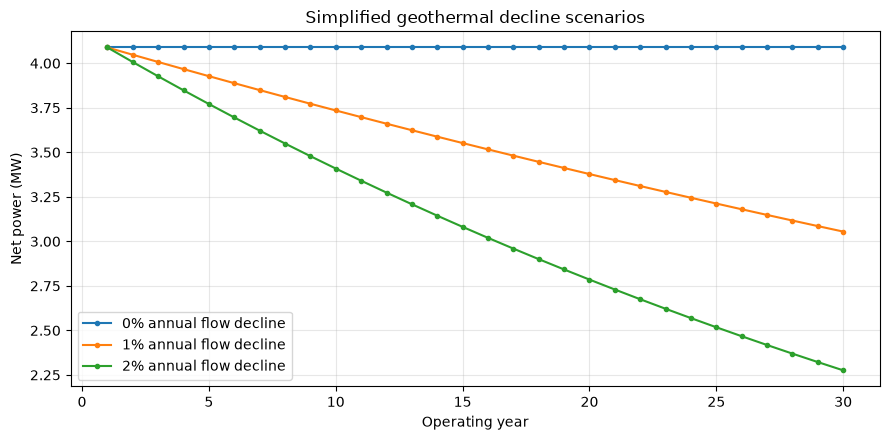

In [2]:
years = np.arange(1, 31)
initial_mass_flow = 90.0
decline_rates = [0.00, 0.01, 0.02]

fig, ax = plt.subplots(figsize=(9, 4.5))
for decline in decline_rates:
    flow = initial_mass_flow * (1 - decline) ** (years - 1)
    net_power = geothermal_net_power_mw(
        flow, production_c=165, reinjection_c=70,
        conversion_efficiency=0.13, parasitic_fraction=0.12,
    )
    ax.plot(years, net_power, marker="o", markersize=3,
            label=f"{decline:.0%} annual flow decline")

ax.set(xlabel="Operating year", ylabel="Net power (MW)",
       title="Simplified geothermal decline scenarios")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()

The plot varies only mass flow. In a real reservoir, temperature, pressure, scaling, downtime, reinjection response, and parasitic pumping may also change.

[Download the theory notebook](geothermalEnergy.ipynb).

## Common mistakes

- Using °C rather than Kelvin in a thermodynamic temperature ratio.
- Calling geothermal gradient a heat flux.
- Ignoring phase change when enthalpy, not constant $c_p\Delta T$, is required.
- Reporting gross power while omitting pumping and auxiliary loads.
- Treating a high subsurface temperature as proof of permeability, flow, or commercial viability.
- Subtracting a fixed decline percentage linearly instead of compounding the retained fraction.

(chapter-practice-20-python-exercises)=
## Practice

[Open the geothermal exercises](../section7/workbook/geothermal.md) in the Applied Python Workbook.

## Check your understanding

Continue with the [geothermal quiz and Python challenge](../section7/renewableEnergyquizzes/geothermalEnergy.md).

## References used in this notebook

<a id="reference-diPippo2016geothermal"></a>

- **diPippo2016geothermal:** DiPippo, Ronald. Geothermal Power Plants: Principles, Applications, Case Studies and Environmental Impact (2016). https://www.sciencedirect.com/book/monograph/9780081008799/geothermal-power-plants
<a id="reference-doeGeothermalElectricity"></a>

- **doeGeothermalElectricity:** U.S. Department of Energy. Geothermal Electricity Generation (2025). https://www.energy.gov/hgeo/geothermal/geothermal-electricity-generation
<a id="reference-doeEGS"></a>

- **doeEGS:** U.S. Department of Energy. Enhanced Geothermal Systems (2025). https://www.energy.gov/hgeo/geothermal/enhanced-geothermal-systems
<a id="reference-grant2011"></a>

- **grant2011:** Grant, Malcolm A. and Bixley, Paul F.. Geothermal Reservoir Engineering (2011). 
<a id="reference-jica2011"></a>

- **jica2011:** Japan International Cooperation Agency. Guideline and Manual for Hydropower Development, Vol. 2: Small Scale Hydropower (2011). 
<a id="reference-wade2003"></a>

- **wade2003:** Wade, Herbert A.. Solar Photovoltaic Systems: Technical Training Manual (2003). 
<a id="reference-foster2010"></a>

- **foster2010:** Foster, Robert and Ghassemi, Majid and Cota, Alma. Solar Energy: Renewable Energy and the Environment (2010). 